# DSCI 552 HW4

Justin Li

zyli@usc.edu

34004214

In [1]:
import itertools
import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
sns.set_style("whitegrid")
np.random.seed(42)
RANDOM_STATE = 42

## 1. Feature creation from Homework 3

Homework 3 covered this part and it is not graded again here, but the models below need
the feature extraction code, so it is repeated. The only change is that the extractor now
takes a parameter l and splits each time series into l near-equal segments before computing
the seven features, which gives 42l features per instance.

In [2]:
ROOT = "../data/AReM"
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
TEST_SETS = {"bending1": [1, 2], "bending2": [1, 2], "cycling": [1, 2, 3],
             "lying": [1, 2, 3], "sitting": [1, 2, 3], "standing": [1, 2, 3],
             "walking": [1, 2, 3]}
FEATS = ["min", "max", "mean", "median", "std", "1stquart", "3rdquart"]
CHOSEN = ["mean", "max", "std"]
SERIES_USED = [1, 2, 6]


def read_instance(path):
    rows = []
    with open(path, encoding="utf-8", errors="replace") as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = [p for p in re.split(r"[,\s]+", line) if p != ""]
            if len(parts) >= 7:
                rows.append([float(x) for x in parts[:7]])
    return pd.DataFrame(rows, columns=["time"] + SERIES)


def load_all():
    out = []
    for act in ACTIVITIES:
        files = [f for f in os.listdir(os.path.join(ROOT, act)) if f.endswith(".csv")]
        files.sort(key=lambda f: int(re.search(r"\d+", f).group()))
        for f in files:
            num = int(re.search(r"\d+", f).group())
            out.append({"activity": act, "dataset": num,
                        "split": "test" if num in TEST_SETS[act] else "train",
                        "binary": "bending" if act.startswith("bending") else "other",
                        "data": read_instance(os.path.join(ROOT, act, f))})
    return out


def segment_features(df, l):
    row = {}
    bounds = np.linspace(0, len(df), l + 1).astype(int)
    for i, s in enumerate(SERIES, start=1):
        v = df[s].values
        for j in range(l):
            seg = v[bounds[j]:bounds[j + 1]]
            suf = f"{i}_{j + 1}" if l > 1 else f"{i}"
            row[f"min{suf}"] = seg.min()
            row[f"max{suf}"] = seg.max()
            row[f"mean{suf}"] = seg.mean()
            row[f"median{suf}"] = np.median(seg)
            row[f"std{suf}"] = seg.std(ddof=1)
            row[f"1stquart{suf}"] = np.percentile(seg, 25)
            row[f"3rdquart{suf}"] = np.percentile(seg, 75)
    return row


def build_table(instances, l):
    X = pd.DataFrame([segment_features(i["data"], l) for i in instances])
    meta = pd.DataFrame([{k: i[k] for k in ("activity", "dataset", "split", "binary")}
                         for i in instances])
    X.index = meta.index = pd.RangeIndex(1, len(instances) + 1, name="Instance")
    return meta, X


instances = load_all()
meta, X1 = build_table(instances, 1)
train_mask = (meta["split"] == "train").values
y_bin = (meta["binary"] == "bending").astype(int).values
y_multi = meta["activity"].values

print("instances:", len(instances))
print("train:", train_mask.sum(), " test:", (~train_mask).sum())
print("bending in train:", y_bin[train_mask].sum(), " bending in test:", y_bin[~train_mask].sum())

instances: 88
train: 69  test: 19
bending in train: 9  bending in test: 4


In [3]:
TABLES = {l: build_table(instances, l)[1] for l in range(1, 21)}
print("feature counts by l:", {l: TABLES[l].shape[1] for l in [1, 2, 5, 10, 20]})

feature counts by l: {1: 42, 2: 84, 5: 210, 10: 420, 20: 840}


The three features chosen in Homework 3 part 1(c)iv were mean, maximum, and standard deviation, and the parts below use those with time series 1, 2, and 6 as the assignment specifies.

## 2(a)i Scatter plots of the selected features, bending versus other

feature columns plotted: ['mean1', 'max1', 'std1', 'mean2', 'max2', 'std2', 'mean6', 'max6', 'std6']


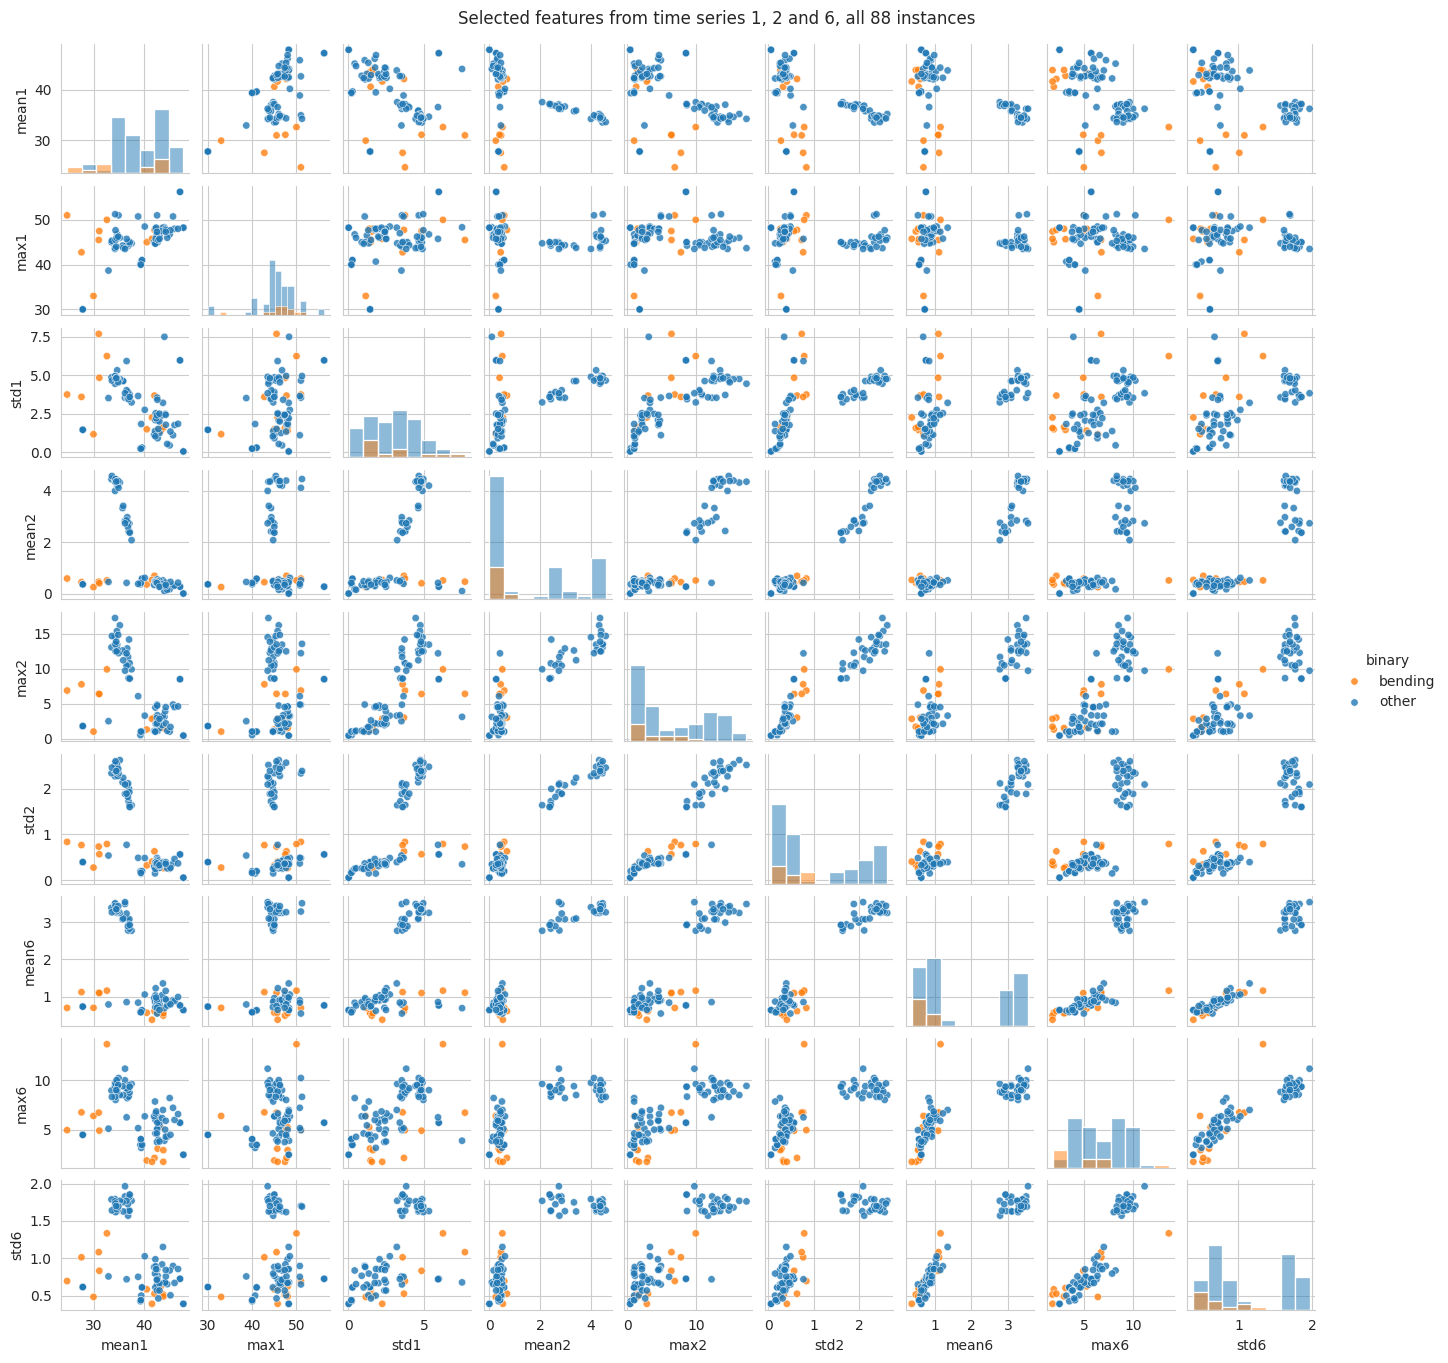

In [4]:
cols_l1 = [f"{f}{s}" for s in SERIES_USED for f in CHOSEN]
pairs_l1 = list(itertools.combinations(cols_l1, 2))
print("feature columns plotted:", cols_l1)

plot_df = pd.concat([meta[["binary"]], X1[cols_l1]], axis=1)
g = sns.pairplot(plot_df, vars=cols_l1, hue="binary",
                 palette={"bending": "tab:orange", "other": "tab:blue"},
                 plot_kws={"s": 28, "alpha": 0.8}, diag_kind="hist", height=1.5)
g.fig.suptitle("Selected features from time series 1, 2 and 6, all 88 instances", y=1.01)
plt.show()

The scatter matrix uses mean, maximum, and standard deviation of time series 1 (avg_rss12), 2 (var_rss12), and 6 (var_rss23), which is nine columns, with color separating bending from the other five activities.

Bending separates well on several pairs. The clearest are the panels involving mean1 and max6, where the bending instances sit in a distinct corner with little overlap. Panels built only from the variance series are noisier, since several non-bending activities also produce low signal variance.

The separation is good enough that a linear boundary looks plausible by eye, which matters for the logistic regression that follows.

## 2(a)ii Scatter plots after splitting each time series in two

columns now: 18 of 84 total features


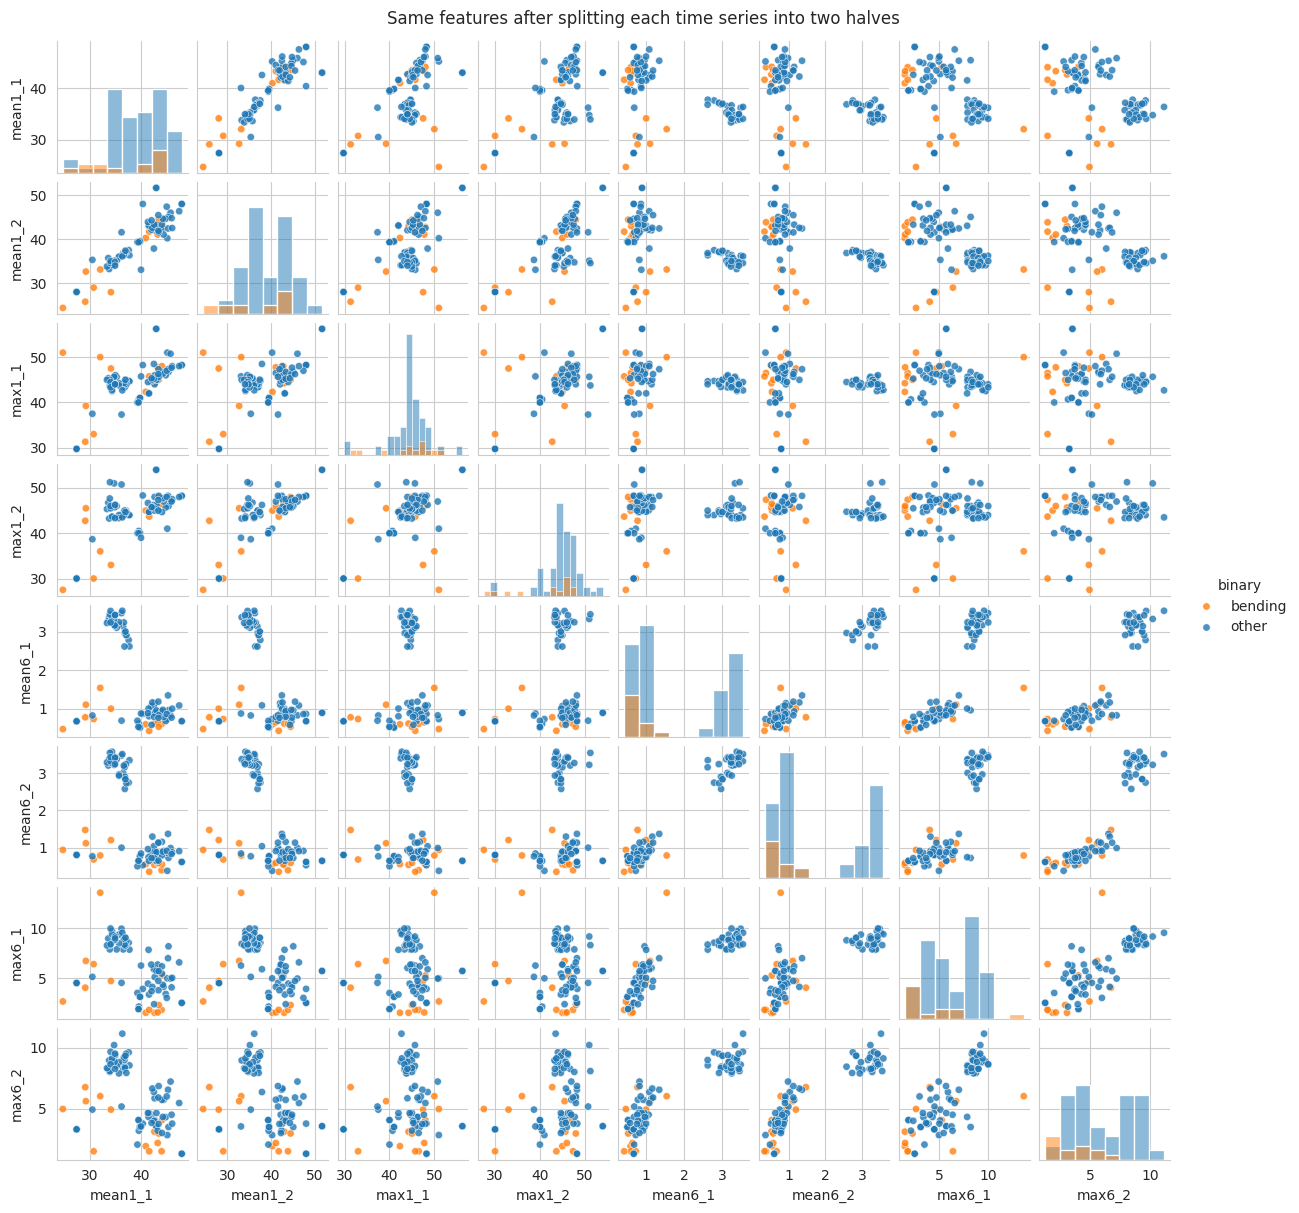

In [5]:
meta2, X2 = build_table(instances, 2)
cols_l2 = [f"{f}{s}_{p}" for s in SERIES_USED for f in CHOSEN for p in (1, 2)]
print("columns now:", len(cols_l2), "of", X2.shape[1], "total features")

subset = [c for c in cols_l2 if c.startswith(("mean1", "max1", "mean6", "max6"))]
plot_df2 = pd.concat([meta[["binary"]], X2[subset]], axis=1)
g = sns.pairplot(plot_df2, vars=subset, hue="binary",
                 palette={"bending": "tab:orange", "other": "tab:blue"},
                 plot_kws={"s": 28, "alpha": 0.8}, diag_kind="hist", height=1.5)
g.fig.suptitle("Same features after splitting each time series into two halves", y=1.01)
plt.show()

In [6]:
def smd(col, Xd):
    a = Xd.loc[train_mask & (y_bin == 1), col]
    b = Xd.loc[train_mask & (y_bin == 0), col]
    pooled = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return abs(a.mean() - b.mean()) / pooled if pooled > 0 else np.nan


sep1 = pd.Series({c: smd(c, X1) for c in cols_l1}).sort_values(ascending=False)
sep2 = pd.Series({c: smd(c, X2) for c in cols_l2}).sort_values(ascending=False)
print("l = 1, top 6 by |standardized mean difference|:")
print(sep1.head(6).round(3).to_string())
print()
print("l = 2, top 6 by |standardized mean difference|:")
print(sep2.head(6).round(3).to_string())
print()
print(f"best single column: l=1 {sep1.max():.3f}  vs  l=2 {sep2.max():.3f}")

l = 1, top 6 by |standardized mean difference|:
mean6    1.174
mean2    1.031
std6     0.929
std2     0.888
max2     0.673
max6     0.527

l = 2, top 6 by |standardized mean difference|:
max6_2     1.252
mean6_2    1.242
std6_2     1.216
mean6_1    1.086
mean2_2    1.044
mean2_1    1.011

best single column: l=1 1.174  vs  l=2 1.252


Splitting each time series in half turns 6 series into 12, so the same three feature types now give 18 columns instead of 9 for these three series, and 84 features overall instead of 42.

There is no considerable difference in the picture. The bending group still occupies the same region and the overlap with the other activities is about the same. The best single column by standardized mean difference improves only slightly, from 1.174 at l = 1 to 1.252 at l = 2, and the ordering of the strongest features barely changes.

This makes sense for these activities. Bending differs from cycling or walking in the overall level and variability of the signal, not in when those levels occur within the two minutes, so cutting the recording in half mostly duplicates the same information. Splitting would help if an activity had a distinctive temporal pattern, such as a burst of movement in the first half only. The cross-validation in the next part tests this properly instead of by eye.

## 2(a)iii Cross-validation over l and p with recursive feature elimination

The right way and the wrong way to cross-validate here.

The wrong way is to run recursive feature elimination once on the whole training set, keep the p features it chooses, and only then start the 5-fold loop on those features. Every fold's validation data helped choose the features, so the validation score is no longer an estimate of performance on unseen data. It will be optimistically biased, and the bias is large when the number of candidate features (up to 840 at l = 20) far exceeds the 69 training instances, because a selector given that much freedom can find features that happen to split the particular sample.

The right way is to put feature selection inside the loop. For each candidate pair (l, p) and each fold, recursive feature elimination is fitted on that fold's training portion only, the top p features are taken from that fold's own ranking, the model is fitted on those features, and the held-out fold is scored. The held-out fold then plays no part in choosing its own features.

Extracting the features from the raw time series is done outside the loop, which is safe because computing a minimum or a mean from one instance's own values never touches the labels or any other instance.

Folds are stratified, since bending is only 9 of the 69 training instances and unstratified folds could easily contain none of it.

One efficiency note: fitting recursive feature elimination down to a single feature produces a full ranking of the features, so one fit per fold serves every candidate p rather than refitting for each.

In [7]:
L_VALUES = list(range(1, 21))
P_GRID = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20]


def plain_lr():
    return LogisticRegression(penalty=None, solver="lbfgs", max_iter=200)


cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
records = []

for l in L_VALUES:
    Xl = TABLES[l].values[train_mask]
    yl = y_bin[train_mask]
    scores = {p: [] for p in P_GRID}
    for tr, va in cv5.split(Xl, yl):
        ranking = RFE(plain_lr(), n_features_to_select=1, step=0.15).fit(Xl[tr], yl[tr])
        order = np.argsort(ranking.ranking_)
        for p in P_GRID:
            if p > Xl.shape[1]:
                continue
            idx = order[:p]
            m = plain_lr().fit(Xl[tr][:, idx], yl[tr])
            scores[p].append(accuracy_score(yl[va], m.predict(Xl[va][:, idx])))
    for p in P_GRID:
        if scores[p]:
            records.append({"l": l, "p": p, "cv_accuracy": np.mean(scores[p]),
                            "cv_std": np.std(scores[p])})

cv_results = pd.DataFrame(records)
best = cv_results.sort_values(["cv_accuracy", "p", "l"],
                              ascending=[False, True, True]).iloc[0]
BEST_L, BEST_P = int(best["l"]), int(best["p"])
print(f"best (l, p) = ({BEST_L}, {BEST_P}), cv accuracy = {best['cv_accuracy']:.4f}")
print()
print(cv_results.sort_values(["cv_accuracy", "p"], ascending=[False, True])
      .head(10).round(4).to_string(index=False))

best (l, p) = (1, 6), cv accuracy = 1.0000

 l  p  cv_accuracy  cv_std
 1  6       1.0000  0.0000
 1  5       0.9857  0.0286
 1  7       0.9857  0.0286
 1  9       0.9857  0.0286
18  9       0.9857  0.0286
 1 20       0.9857  0.0286
 4  2       0.9714  0.0571
 1  8       0.9714  0.0571
20  9       0.9714  0.0350
 1 10       0.9714  0.0571


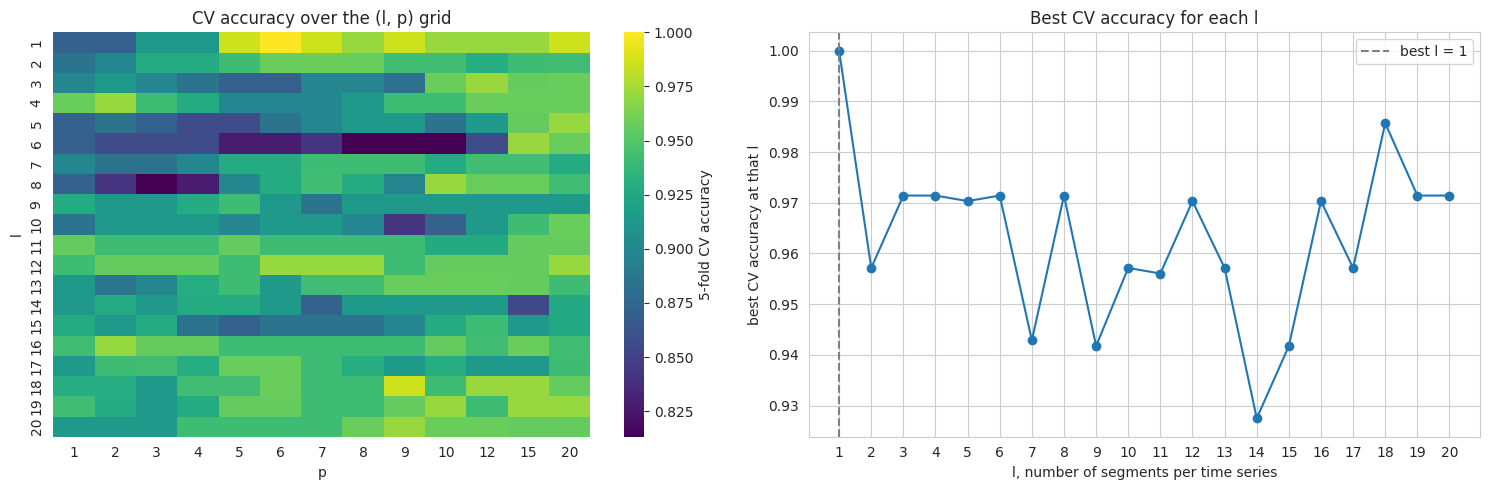

In [8]:
pivot = cv_results.pivot(index="l", columns="p", values="cv_accuracy")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(pivot, annot=False, cmap="viridis", ax=axes[0],
            cbar_kws={"label": "5-fold CV accuracy"})
axes[0].set_title("CV accuracy over the (l, p) grid")

by_l = cv_results.loc[cv_results.groupby("l")["cv_accuracy"].idxmax()]
axes[1].plot(by_l["l"], by_l["cv_accuracy"], "o-")
axes[1].axvline(BEST_L, color="gray", ls="--", label=f"best l = {BEST_L}")
axes[1].set_xlabel("l, number of segments per time series")
axes[1].set_ylabel("best CV accuracy at that l")
axes[1].set_title("Best CV accuracy for each l")
axes[1].set_xticks(L_VALUES)
axes[1].legend()
plt.tight_layout()
plt.show()

In [9]:
X_best = TABLES[BEST_L]
Xtr_all, ytr = X_best.values[train_mask], y_bin[train_mask]
Xte_all, yte = X_best.values[~train_mask], y_bin[~train_mask]

final_rfe = RFE(plain_lr(), n_features_to_select=BEST_P, step=0.15).fit(Xtr_all, ytr)
sel_idx = np.where(final_rfe.support_)[0]
SELECTED = list(X_best.columns[sel_idx])
Xtr, Xte = Xtr_all[:, sel_idx], Xte_all[:, sel_idx]
print("selected features:", SELECTED)

selected features: ['mean1', '3rdquart1', 'min5', 'max5', 'mean5', 'max6']


The grid search returns l = 1 and p = 6 with a 5-fold cross-validation accuracy of 1.0000. The six features kept by recursive feature elimination are mean1, 3rdquart1, min5, max5, mean5, and max6.

l = 1 winning means no splitting helps, which confirms what the scatter plots in 2(a)ii suggested. The binary problem is easy enough that whole-series summaries already separate the classes, and splitting only multiplies the number of correlated features that the selector has to sift through. Several larger l values reach 0.9857, so the surface is quite flat, but nothing beats leaving the series whole.

Note that a cross-validation accuracy of exactly 1.0 is a warning as much as a result. It means no fold ever misclassified an instance, which points at classes that are linearly separable. Part 2(a)vi returns to this.

## 2(a)iv Confusion matrix, ROC, AUC, and parameters on the training set

In [10]:
Xtr_sm = sm.add_constant(Xtr, has_constant="add")
logit = sm.Logit(ytr, Xtr_sm).fit(disp=0, maxiter=100)

params = pd.DataFrame({
    "term": ["const"] + SELECTED,
    "beta": logit.params,
    "std_err": logit.bse,
    "z": logit.tvalues,
    "p_value": logit.pvalues,
}).set_index("term")
print("converged:", logit.mle_retvals["converged"])
print("log-likelihood:", round(logit.llf, 8))
print()
params.round(4)

converged: False
log-likelihood: -0.0



,beta,std_err,z,p_value
term,,,,
const,-17.3279,1.6463e+07,-0.0,1.0
mean1,-2.9502,9.4329e+05,-0.0,1.0
3rdquart1,-3.5936,1.2104e+06,-0.0,1.0
min5,4.4722,3.0300e+05,0.0,1.0
max5,6.1132,3.9901e+05,0.0,1.0
mean5,5.1368,5.1920e+05,0.0,1.0
max6,-4.9719,2.5097e+05,-0.0,1.0


In [11]:
ridge = sm.Logit(ytr, Xtr_sm).fit_regularized(alpha=1e-4, disp=0, maxiter=500)
pd.DataFrame({"term": ["const"] + SELECTED, "beta_small_ridge": ridge.params}).set_index("term").round(4)

,beta_small_ridge
term,
const,-0.0066
mean1,-0.0509
3rdquart1,-3.0534
min5,1.5272
max5,3.0181
mean5,2.0130
max6,-1.8657


In [12]:
model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000).fit(Xtr, ytr)
pred_tr = model.predict(Xtr)
score_tr = model.predict_proba(Xtr)[:, 1]

cm_tr = confusion_matrix(ytr, pred_tr)
print("training confusion matrix:")
print(pd.DataFrame(cm_tr, index=["actual other", "actual bending"],
                   columns=["pred other", "pred bending"]).to_string())
print()
print("training accuracy:", round(accuracy_score(ytr, pred_tr), 4))
print("training AUC:", round(roc_auc_score(ytr, score_tr), 4))

training confusion matrix:
                pred other  pred bending
actual other            60             0
actual bending           0             9

training accuracy: 1.0
training AUC: 1.0


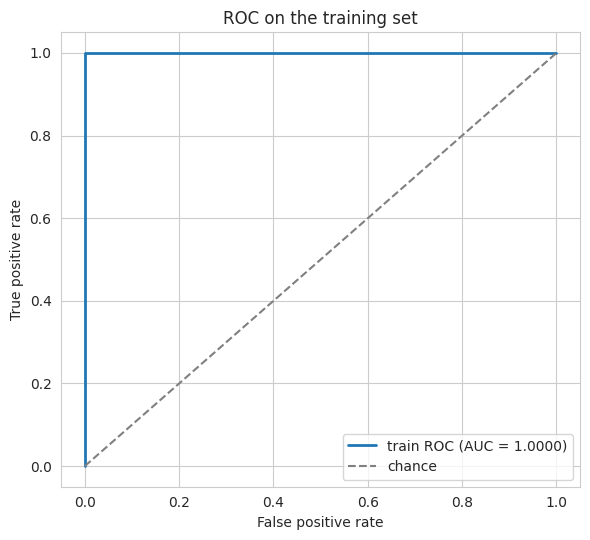

In [13]:
fpr_tr, tpr_tr, _ = roc_curve(ytr, score_tr)
plt.figure(figsize=(6, 5.5))
plt.plot(fpr_tr, tpr_tr, lw=2, label=f"train ROC (AUC = {auc(fpr_tr, tpr_tr):.4f})")
plt.plot([0, 1], [0, 1], ls="--", color="gray", label="chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC on the training set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The training confusion matrix is 60 correct for other and 9 correct for bending, with no errors in either direction. Training accuracy is 1.0000 and the training AUC is 1.0000.

The parameter table is where the problem shows. The maximum likelihood fit does not converge, the log-likelihood reaches 0, and the standard errors come back on the order of 1e6 to 1e7, which drives every z statistic to 0 and every p-value to 1.0000 at four decimal places. Those p-values are not evidence that the features are useless. They are the arithmetic consequence of standard errors that have diverged, and the Wald test is meaningless here.

The reason is perfect separation. When a hyperplane separates the two classes exactly, the likelihood keeps increasing as the coefficients grow without bound, so no finite maximum exists. The optimizer stops only because it hits the iteration cap, and whatever coefficients it reports depend on where it stopped rather than on the data.

The second table adds a very small ridge penalty, which makes the problem strictly concave and gives a finite solution. Those coefficients are the ones worth reading: 3rdquart1 and max6 push toward other, while max5, mean5, and min5 push toward bending. The sklearn fit used for the metrics behaves the same way, with the lbfgs iteration cap acting as the stopping rule.

## 2(a)v Performance on the test set

In [14]:
pred_te = model.predict(Xte)
score_te = model.predict_proba(Xte)[:, 1]

cm_te = confusion_matrix(yte, pred_te)
print("test confusion matrix:")
print(pd.DataFrame(cm_te, index=["actual other", "actual bending"],
                   columns=["pred other", "pred bending"]).to_string())
print()
acc_te = accuracy_score(yte, pred_te)
print("test accuracy:", round(acc_te, 4))
print("test error:", round(1 - acc_te, 4))
print("test AUC:", round(roc_auc_score(yte, score_te), 4))
print("cross-validation accuracy from 2(a)iii:", round(best["cv_accuracy"], 4))

test confusion matrix:
                pred other  pred bending
actual other            15             0
actual bending           0             4

test accuracy: 1.0
test error: 0.0
test AUC: 1.0
cross-validation accuracy from 2(a)iii: 1.0


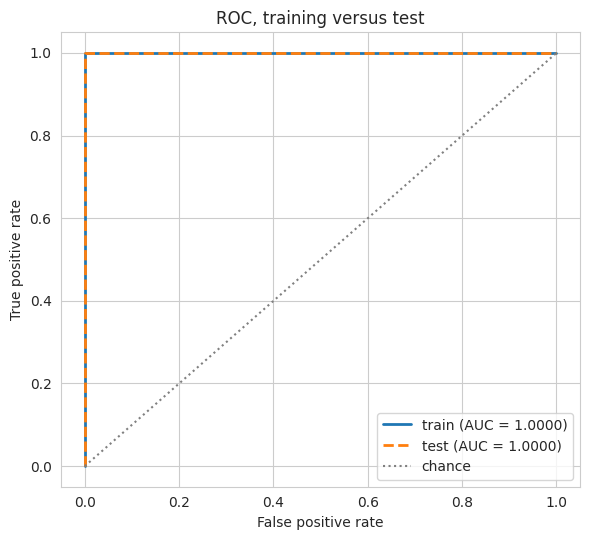

In [15]:
fpr_te, tpr_te, _ = roc_curve(yte, score_te)
plt.figure(figsize=(6, 5.5))
plt.plot(fpr_tr, tpr_tr, lw=2, label=f"train (AUC = {auc(fpr_tr, tpr_tr):.4f})")
plt.plot(fpr_te, tpr_te, lw=2, ls="--", label=f"test (AUC = {auc(fpr_te, tpr_te):.4f})")
plt.plot([0, 1], [0, 1], ls=":", color="gray", label="chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC, training versus test")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The test set is broken into the same l = 1 segments as the training set and the same six features are extracted from it. The test confusion matrix is 15 correct for other and 4 correct for bending, with no errors, so test accuracy is 1.0000, test error is 0.0000, and the test AUC is 1.0000.

This matches the cross-validation accuracy of 1.0000 exactly. Agreement between the two is reassuring in the sense that the cross-validation estimate was not optimistic, which suggests the nested selection procedure in 2(a)iii was set up correctly.

The result should still be read with care. The test set holds only 19 instances, 4 of which are bending, so a single mistake would have moved accuracy to 0.9474. Perfect accuracy on 19 points is consistent with a wide range of true error rates, and the honest summary is that the classifier is very good on this problem rather than that its error rate is zero.

## 2(a)vi Are the classes well separated?

In [16]:
svc = LinearSVC(C=1e6, max_iter=500000).fit(Xtr, ytr)
print("hard-margin linear SVC training accuracy:", round(svc.score(Xtr, ytr), 4))
print()
print("statsmodels Logit converged:", logit.mle_retvals["converged"])
print("largest standard error:", f"{logit.bse.max():.3e}")
print("smallest p-value in the fit:", round(logit.pvalues.min(), 6))
print("log-likelihood at the reported optimum:", round(logit.llf, 8))
print()
print("fitted probabilities on the training set:")
print("   minimum:", f"{score_tr.min():.3e}", "  maximum:", f"{1 - score_tr.max():.3e}",
      "below 1")
print("   misclassified training instances:", int((pred_tr != ytr).sum()))

hard-margin linear SVC training accuracy: 1.0

statsmodels Logit converged: False
largest standard error: 1.646e+07
smallest p-value in the fit: 0.999984
log-likelihood at the reported optimum: -0.0

fitted probabilities on the training set:
   minimum: 2.749e-38   maximum: 0.000e+00 below 1
   misclassified training instances: 0


Yes. The classes are linearly separable, and that is what makes the logistic regression parameters unstable.

A hard-margin linear support vector classifier reaches 1.0000 training accuracy, which means some hyperplane puts every bending instance on one side and every other instance on the other with no violations. Once that is true, the logistic likelihood has no finite maximum: scaling any separating coefficient vector upward pushes every fitted probability closer to 0 or 1 and the log-likelihood closer to 0, so the optimizer keeps walking in that direction until an iteration cap or a tolerance stops it.

The symptoms are all present. The fit reports not converged, the log-likelihood is 0 to eight decimal places, the largest standard error is on the order of 1e7, and the smallest p-value in the whole fit is 0.999984. The fitted probabilities are numerically 0 and 1 rather than values strictly inside the interval.

The practical consequence is that the coefficients and their p-values cannot be interpreted and should not be used for inference, even though the classifier predicts well. Something has to pin the solution down: a penalty, as in part 2(b), or a capped iteration count, which is what the footnote in the assignment suggests. The accuracy results above are unaffected, because the decision boundary is stable even when its scale is not.

## 2(a)vii Class imbalance and case-control sampling

In [17]:
print("training counts:", dict(zip(["other", "bending"], np.bincount(ytr))))
print("test counts:    ", dict(zip(["other", "bending"], np.bincount(yte))))
print("imbalance ratio in training:", round(np.bincount(ytr)[0] / np.bincount(ytr)[1], 2), "to 1")

training counts: {'other': np.int64(60), 'bending': np.int64(9)}
test counts:     {'other': np.int64(15), 'bending': np.int64(4)}
imbalance ratio in training: 6.67 to 1


In [18]:
balanced = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000,
                              class_weight="balanced").fit(Xtr, ytr)
pb_tr = balanced.predict(Xtr)
pb_te = balanced.predict(Xte)
sb_tr = balanced.predict_proba(Xtr)[:, 1]
sb_te = balanced.predict_proba(Xte)[:, 1]

print("case-control weighted model, training confusion matrix:")
print(pd.DataFrame(confusion_matrix(ytr, pb_tr), index=["actual other", "actual bending"],
                   columns=["pred other", "pred bending"]).to_string())
print("training accuracy:", round(accuracy_score(ytr, pb_tr), 4),
      " AUC:", round(roc_auc_score(ytr, sb_tr), 4))
print()
print("case-control weighted model, test confusion matrix:")
print(pd.DataFrame(confusion_matrix(yte, pb_te), index=["actual other", "actual bending"],
                   columns=["pred other", "pred bending"]).to_string())
print("test accuracy:", round(accuracy_score(yte, pb_te), 4),
      " AUC:", round(roc_auc_score(yte, sb_te), 4))

case-control weighted model, training confusion matrix:
                pred other  pred bending
actual other            60             0
actual bending           0             9
training accuracy: 1.0  AUC: 1.0

case-control weighted model, test confusion matrix:
                pred other  pred bending
actual other            15             0
actual bending           0             4
test accuracy: 1.0  AUC: 1.0


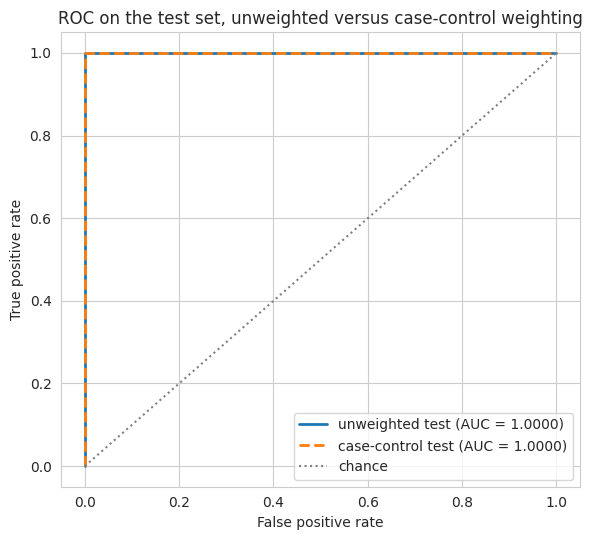

In [19]:
fpr_b, tpr_b, _ = roc_curve(yte, sb_te)
plt.figure(figsize=(6, 5.5))
plt.plot(fpr_te, tpr_te, lw=2, label=f"unweighted test (AUC = {auc(fpr_te, tpr_te):.4f})")
plt.plot(fpr_b, tpr_b, lw=2, ls="--",
         label=f"case-control test (AUC = {auc(fpr_b, tpr_b):.4f})")
plt.plot([0, 1], [0, 1], ls=":", color="gray", label="chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC on the test set, unweighted versus case-control weighting")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Yes, the classes are imbalanced. The training set holds 60 other against 9 bending, a ratio of 6.67 to 1, and the test set holds 15 against 4. Bending is only about 13 percent of the data, which follows from the folder counts: bending1 and bending2 together hold 13 of the 88 instances while the other five activities hold 15 each.

The confusion matrices in 2(a)iv and 2(a)v do not show the usual damage from imbalance, though, because there are no errors at all in either one. The classifier never takes the lazy option of predicting the majority class, so the imbalance is present in the data without being visible in the results.

The case-control model reweights each class by the inverse of its frequency, so the 9 bending instances carry 60/9 times the weight they otherwise would, which is equivalent to resampling the rare class up to parity. Its confusion matrices are identical to the unweighted ones, training and test accuracy stay at 1.0000, and both AUCs stay at 1.0000.

That is the expected outcome when the classes are already separable. Reweighting shifts the intercept to move the decision threshold toward the rare class, but when no instances sit near the boundary there is nothing for the shift to reclassify. The adjustment would matter on a harder problem, or if the goal were to trade false positives for recall on bending.

## 2(b)i L1-penalized logistic regression

Here variable selection comes from the L1 penalty instead of from p-values or recursive elimination, so both l and the penalty weight have to be cross-validated. The budget C in scikit-learn is the inverse of the penalty weight, so small C means heavy shrinkage. Features are standardized inside the pipeline, which the assignment footnote recommends, and the scaler is fitted within each fold so no information crosses from the validation part.

In [20]:
C_GRID = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]


def l1_pipe(C):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=5000),
    )


rows = []
for l in L_VALUES:
    Xl = TABLES[l].values[train_mask]
    yl = y_bin[train_mask]
    for C_val in C_GRID:
        accs = [accuracy_score(yl[va], l1_pipe(C_val).fit(Xl[tr], yl[tr]).predict(Xl[va]))
                for tr, va in cv5.split(Xl, yl)]
        rows.append({"l": l, "C": C_val, "cv_accuracy": np.mean(accs),
                     "cv_std": np.std(accs)})

l1_results = pd.DataFrame(rows)
best_l1 = l1_results.sort_values(["cv_accuracy", "C", "l"],
                                 ascending=[False, True, True]).iloc[0]
L1_L, L1_C = int(best_l1["l"]), float(best_l1["C"])
print(f"best (l, C) = ({L1_L}, {L1_C}), cv accuracy = {best_l1['cv_accuracy']:.4f}")
print()
print(l1_results.sort_values(["cv_accuracy", "C"], ascending=[False, True])
      .head(10).round(4).to_string(index=False))

best (l, C) = (12, 0.5), cv accuracy = 0.9857

 l   C  cv_accuracy  cv_std
12 0.5       0.9857  0.0286
 3 0.5       0.9714  0.0350
 4 0.5       0.9714  0.0350
13 0.5       0.9714  0.0350
18 0.5       0.9714  0.0350
11 1.0       0.9714  0.0350
12 1.0       0.9714  0.0350
13 1.0       0.9714  0.0350
18 1.0       0.9714  0.0350
19 1.0       0.9714  0.0350


In [21]:
X_l1 = TABLES[L1_L]
l1_model = l1_pipe(L1_C).fit(X_l1.values[train_mask], y_bin[train_mask])
coef_l1 = l1_model[-1].coef_[0]
kept = np.where(coef_l1 != 0)[0]
print(f"features kept: {len(kept)} of {X_l1.shape[1]}")
print(pd.Series(coef_l1[kept], index=X_l1.columns[kept]).round(4).to_string())

features kept: 7 of 504
max1_7        -0.4927
median4_9     -0.0052
3rdquart4_9   -0.0004
median5_2      0.0617
1stquart5_2    1.6173
min5_11        0.3306
max6_11       -0.3080


In [22]:
p_tr_l1 = l1_model.predict(X_l1.values[train_mask])
p_te_l1 = l1_model.predict(X_l1.values[~train_mask])
s_tr_l1 = l1_model.predict_proba(X_l1.values[train_mask])[:, 1]
s_te_l1 = l1_model.predict_proba(X_l1.values[~train_mask])[:, 1]

print("training confusion matrix:")
print(pd.DataFrame(confusion_matrix(ytr, p_tr_l1), index=["actual other", "actual bending"],
                   columns=["pred other", "pred bending"]).to_string())
print("training accuracy:", round(accuracy_score(ytr, p_tr_l1), 4),
      " AUC:", round(roc_auc_score(ytr, s_tr_l1), 4))
print()
print("test confusion matrix:")
print(pd.DataFrame(confusion_matrix(yte, p_te_l1), index=["actual other", "actual bending"],
                   columns=["pred other", "pred bending"]).to_string())
acc_l1 = accuracy_score(yte, p_te_l1)
print("test accuracy:", round(acc_l1, 4), " test error:", round(1 - acc_l1, 4),
      " AUC:", round(roc_auc_score(yte, s_te_l1), 4))

training confusion matrix:
                pred other  pred bending
actual other            60             0
actual bending           0             9
training accuracy: 1.0  AUC: 1.0

test confusion matrix:
                pred other  pred bending
actual other            15             0
actual bending           1             3
test accuracy: 0.9474  test error: 0.0526  AUC: 1.0


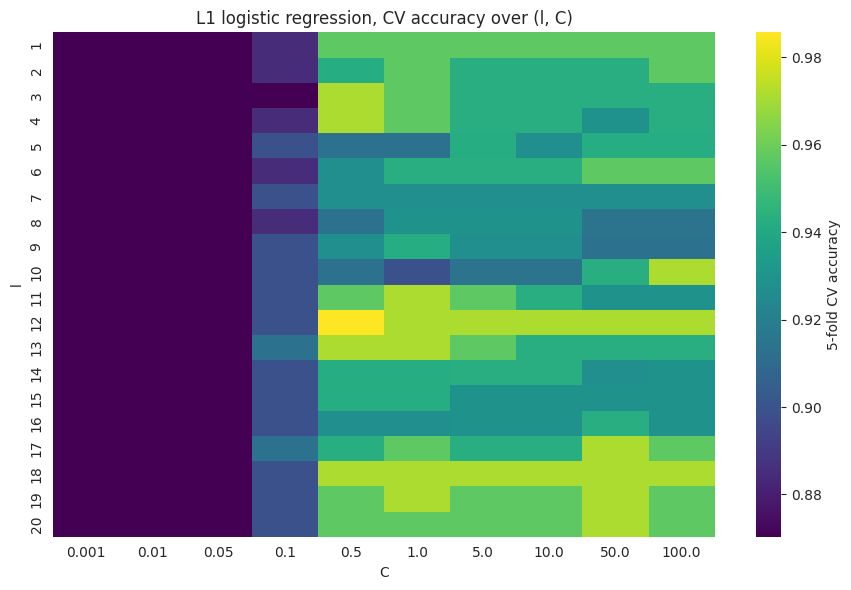

In [23]:
pivot_l1 = l1_results.pivot(index="l", columns="C", values="cv_accuracy")
plt.figure(figsize=(9, 6))
sns.heatmap(pivot_l1, annot=False, cmap="viridis", cbar_kws={"label": "5-fold CV accuracy"})
plt.title("L1 logistic regression, CV accuracy over (l, C)")
plt.tight_layout()
plt.show()

Cross-validation picks l = 12 and C = 0.5, with a 5-fold accuracy of 0.9857. The fitted model keeps 7 nonzero coefficients out of 504 candidate features, so the penalty discards about 99 percent of them.

On the training set the model is perfect, 60 and 9 with no errors. On the test set it misclassifies one bending instance as other, giving 15 and 3 with one error, so test accuracy is 0.9474 and test error is 0.0526. The test AUC is still 1.0000, which means the ranking of instances by predicted probability is perfect and only the 0.5 threshold is in the wrong place for that one instance.

It is worth noticing that this model selects a much larger l than the p-value route did. With the penalty controlling complexity directly, the extra segments are no longer costly, so cross-validation is free to pick a representation that splits each series into 12 parts and then lets L1 keep the handful of segment features that matter.

## 2(b)ii L1 penalty versus variable selection with p-values

In [24]:
comparison = pd.DataFrame([
    {"method": "RFE then unpenalized logistic (2a)", "l": BEST_L, "setting": f"p = {BEST_P}",
     "features_used": BEST_P, "cv_accuracy": best["cv_accuracy"],
     "test_accuracy": acc_te, "test_error": 1 - acc_te,
     "test_auc": roc_auc_score(yte, score_te)},
    {"method": "L1-penalized logistic (2b)", "l": L1_L, "setting": f"C = {L1_C}",
     "features_used": len(kept), "cv_accuracy": best_l1["cv_accuracy"],
     "test_accuracy": acc_l1, "test_error": 1 - acc_l1,
     "test_auc": roc_auc_score(yte, s_te_l1)},
]).set_index("method")
comparison.round(4)

,l,setting,features_used,cv_accuracy,test_accuracy,test_error,test_auc
method,,,,,,,
RFE then unpenalized logistic (2a),1,p = 6,6,1.0000,1.0000,0.0000,1.0
L1-penalized logistic (2b),12,C = 0.5,7,0.9857,0.9474,0.0526,1.0


On this dataset the recursive elimination route performs slightly better. It reaches 1.0000 cross-validation accuracy against 0.9857 for L1, and 1.0000 test accuracy against 0.9474, using 6 features instead of 7. Both reach a test AUC of 1.0000, so the gap comes down to one threshold decision on one instance, and with 19 test points that difference is well inside noise. Calling them equivalent in accuracy is the fair reading.

L1 is much easier to implement, and that is the real difference. It needs one estimator and a grid over C, and the penalty performs selection and fitting in a single fit, so the whole search is a plain nested loop. The p-value route needs a separate selection step inside every fold, and the p-values it is supposed to use are exactly the quantities that part 2(a)vi showed to be meaningless under perfect separation. That is why recursive feature elimination stands in for them here. Fitting an unpenalized model to a separable problem is also numerically unstable, while L1 makes the objective strictly convex and gives a unique, finite solution.

L1 also scales better. At l = 12 there are 504 candidate features, and recursive elimination has to refit the model repeatedly as it strips them away, whereas the penalty handles that in one pass. For a problem with more features than this one, L1 would be the practical choice even if its accuracy were slightly lower.

## 2(c)i Multi-class classification with L1-penalized multinomial regression

In [25]:
print("training class counts:")
print(pd.Series(y_multi[train_mask]).value_counts().to_string())
min_class = pd.Series(y_multi[train_mask]).value_counts().min()
N_SPLITS_MULTI = int(min(5, min_class))
print()
print("least populated training class has", min_class,
      "instances, so stratified CV uses", N_SPLITS_MULTI, "folds")
cv_multi = StratifiedKFold(n_splits=N_SPLITS_MULTI, shuffle=True, random_state=RANDOM_STATE)
CLASSES = sorted(np.unique(y_multi))

training class counts:
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4

least populated training class has 4 instances, so stratified CV uses 4 folds


In [26]:
C_GRID_MULTI = [0.01, 0.1, 1, 10, 100]


def l1_multinomial(C):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=2000, tol=1e-3,
                           random_state=RANDOM_STATE),
    )


rows = []
for l in L_VALUES:
    Xl = TABLES[l].values[train_mask]
    yl = y_multi[train_mask]
    for C_val in C_GRID_MULTI:
        accs = [accuracy_score(yl[va],
                               l1_multinomial(C_val).fit(Xl[tr], yl[tr]).predict(Xl[va]))
                for tr, va in cv_multi.split(Xl, yl)]
        rows.append({"l": l, "C": C_val, "cv_accuracy": np.mean(accs)})

multi_results = pd.DataFrame(rows)
best_multi = multi_results.sort_values(["cv_accuracy", "C", "l"],
                                       ascending=[False, True, True]).iloc[0]
M_L, M_C = int(best_multi["l"]), float(best_multi["C"])
print(f"best (l, C) = ({M_L}, {M_C}), cv accuracy = {best_multi['cv_accuracy']:.4f}")
print()
print(multi_results.sort_values("cv_accuracy", ascending=False).head(8).round(4).to_string(index=False))

best (l, C) = (1, 1.0), cv accuracy = 0.9142

 l     C  cv_accuracy
 1   1.0       0.9142
 2 100.0       0.9126
 5 100.0       0.8987
 6 100.0       0.8987
 4 100.0       0.8840
 7 100.0       0.8840
 1  10.0       0.8840
 3 100.0       0.8840


In [27]:
X_multi = TABLES[M_L]
multi_model = l1_multinomial(M_C).fit(X_multi.values[train_mask], y_multi[train_mask])
pred_multi = multi_model.predict(X_multi.values[~train_mask])
proba_multi = multi_model.predict_proba(X_multi.values[~train_mask])

acc_multi = accuracy_score(y_multi[~train_mask], pred_multi)
used = int((multi_model[-1].coef_ != 0).any(axis=0).sum())
print(f"features used: {used} of {X_multi.shape[1]}")
print("test accuracy:", round(acc_multi, 4), " test error:", round(1 - acc_multi, 4))
print()
print("test confusion matrix:")
print(pd.DataFrame(confusion_matrix(y_multi[~train_mask], pred_multi, labels=CLASSES),
                   index=[f"actual {c}" for c in CLASSES],
                   columns=[f"pred {c}" for c in CLASSES]).to_string())

features used: 22 of 42
test accuracy: 0.8947  test error: 0.1053

test confusion matrix:
                 pred bending1  pred bending2  pred cycling  pred lying  pred sitting  pred standing  pred walking
actual bending1              2              0             0           0             0              0             0
actual bending2              0              2             0           0             0              0             0
actual cycling               0              0             3           0             0              0             0
actual lying                 0              0             0           3             0              0             0
actual sitting               0              0             0           0             2              1             0
actual standing              0              0             0           0             1              2             0
actual walking               0              0             0           0             0              0     

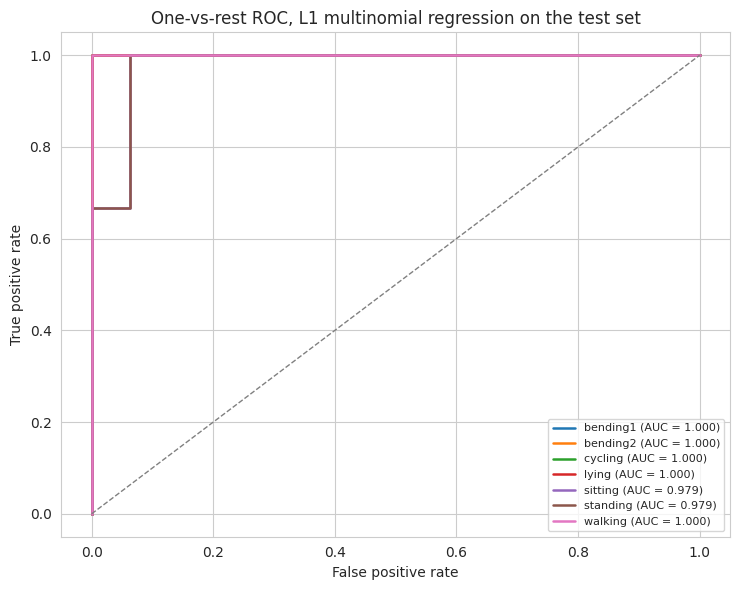

macro-averaged one-vs-rest AUC: 0.994


In [28]:
def plot_multiclass_roc(y_true, proba, classes, title):
    plt.figure(figsize=(7.5, 6))
    aucs = {}
    for i, c in enumerate(classes):
        yb = (y_true == c).astype(int)
        if yb.sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(yb, proba[:, i])
        a = auc(fpr, tpr)
        aucs[c] = a
        plt.plot(fpr, tpr, lw=1.8, label=f"{c} (AUC = {a:.3f})")
    plt.plot([0, 1], [0, 1], ls="--", color="gray", lw=1)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()
    return aucs


aucs_multi = plot_multiclass_roc(y_multi[~train_mask], proba_multi, multi_model.classes_,
                                 "One-vs-rest ROC, L1 multinomial regression on the test set")
macro_auc_multi = roc_auc_score(y_multi[~train_mask], proba_multi, multi_class="ovr",
                                average="macro", labels=multi_model.classes_)
print("macro-averaged one-vs-rest AUC:", round(macro_auc_multi, 4))

Cross-validation for the seven-class problem uses 4 folds rather than 5. The least populated training class is bending2 with only 4 instances, and stratified 5-fold splitting would leave at least one fold with no bending2 at all, which makes the accuracy on that fold meaningless. Four folds is the largest number that keeps every class present in every split.

The best pair is l = 1 and C = 1.0, with a cross-validation accuracy of 0.9142. The fitted model keeps 22 of the 42 features. As in the binary problem, leaving the time series whole wins, so the activities differ in overall signal level and variability rather than in when those levels occur.

Test accuracy is 0.8947 and test error is 0.1053, which is 2 errors out of 19 instances. The macro-averaged one-vs-rest AUC is 0.9940.

The confusion matrix shows exactly where the difficulty is. Both bendings, cycling, lying, and walking are classified perfectly. The only mistakes are one sitting predicted as standing and one standing predicted as sitting. That is unsurprising: both are stationary postures with a motionless subject, so the received signal strength looks similar, whereas cycling and walking produce distinctive movement signatures and the two bending types produce distinctive geometry.

On multiclass ROC, a single curve is not defined for seven classes, so the standard approach is one-vs-rest: for each class in turn, treat it as positive and all others as negative, which gives seven binary ROC curves and seven AUCs that can be averaged. The macro average weights each class equally, which is the right choice here because the rare bending classes matter as much as the common ones.

## 2(c)ii Naive Bayes with Gaussian and Multinomial priors

In [29]:
nb_rows = []
nb_fitted = {}
for name, make in [("GaussianNB", GaussianNB), ("MultinomialNB", MultinomialNB)]:
    per_l = []
    for l in L_VALUES:
        Xl = TABLES[l].values[train_mask]
        yl = y_multi[train_mask]
        accs = [accuracy_score(yl[va], make().fit(Xl[tr], yl[tr]).predict(Xl[va]))
                for tr, va in cv_multi.split(Xl, yl)]
        per_l.append({"l": l, "cv_accuracy": np.mean(accs)})
    per_l = pd.DataFrame(per_l)
    bl = int(per_l.sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]["l"])
    Xn = TABLES[bl]
    m = make().fit(Xn.values[train_mask], y_multi[train_mask])
    pred = m.predict(Xn.values[~train_mask])
    proba = m.predict_proba(Xn.values[~train_mask])
    a = accuracy_score(y_multi[~train_mask], pred)
    nb_fitted[name] = {"model": m, "l": bl, "pred": pred, "proba": proba, "per_l": per_l}
    nb_rows.append({"model": name, "best_l": bl, "cv_accuracy": per_l["cv_accuracy"].max(),
                    "test_accuracy": a, "test_error": 1 - a,
                    "macro_auc": roc_auc_score(y_multi[~train_mask], proba,
                                               multi_class="ovr", average="macro",
                                               labels=m.classes_)})

pd.DataFrame(nb_rows).set_index("model").round(4)

,best_l,cv_accuracy,test_accuracy,test_error,macro_auc
model,,,,,
GaussianNB,1,0.8415,0.8947,0.1053,0.9643
MultinomialNB,7,0.8832,0.7368,0.2632,0.9779


In [30]:
for name in ["GaussianNB", "MultinomialNB"]:
    info = nb_fitted[name]
    print(f"=== {name} (l = {info['l']}) test confusion matrix ===")
    print(pd.DataFrame(confusion_matrix(y_multi[~train_mask], info["pred"], labels=CLASSES),
                       index=[f"actual {c}" for c in CLASSES],
                       columns=[f"pred {c}" for c in CLASSES]).to_string())
    print()

=== GaussianNB (l = 1) test confusion matrix ===
                 pred bending1  pred bending2  pred cycling  pred lying  pred sitting  pred standing  pred walking
actual bending1              2              0             0           0             0              0             0
actual bending2              0              2             0           0             0              0             0
actual cycling               0              0             3           0             0              0             0
actual lying                 0              0             0           2             1              0             0
actual sitting               0              0             0           0             3              0             0
actual standing              0              0             0           0             1              2             0
actual walking               0              0             0           0             0              0             3

=== MultinomialNB (l = 7) test

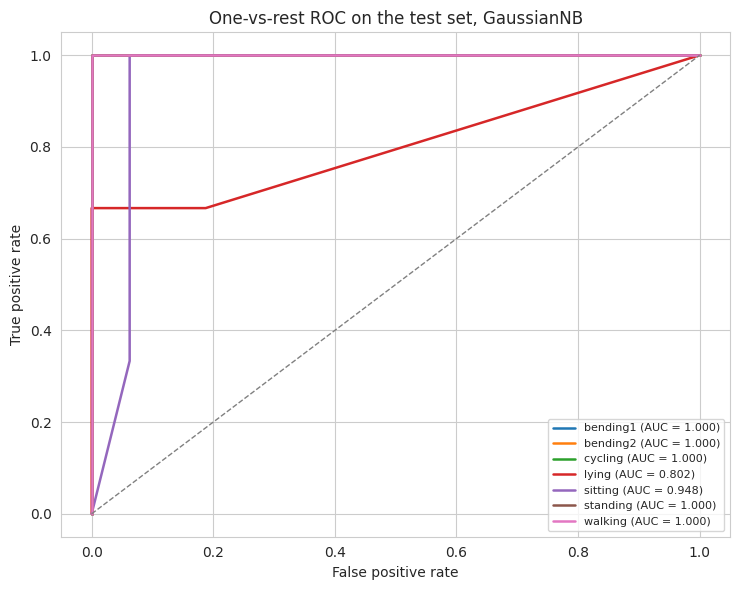

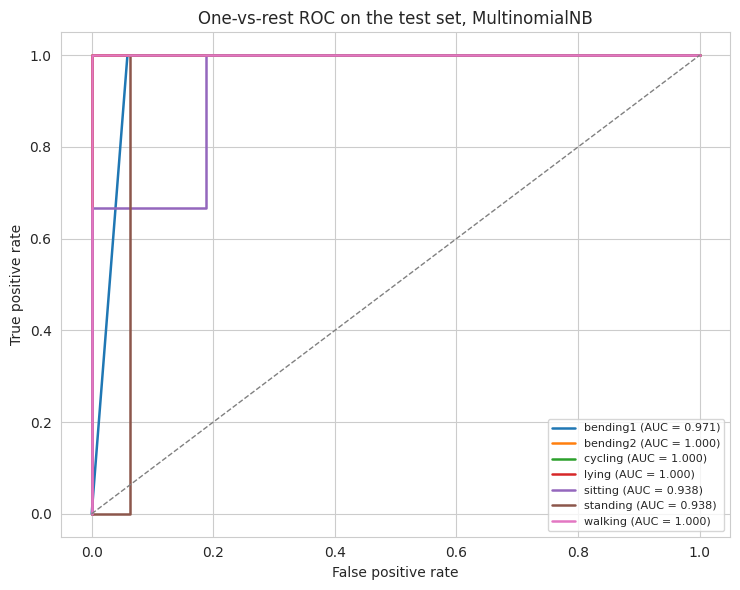

In [31]:
for name in ["GaussianNB", "MultinomialNB"]:
    info = nb_fitted[name]
    plot_multiclass_roc(y_multi[~train_mask], info["proba"], info["model"].classes_,
                        f"One-vs-rest ROC on the test set, {name}")

The two priors behave very differently.

Gaussian Naive Bayes picks l = 1, reaching a cross-validation accuracy of 0.8415, a test accuracy of 0.8947, a test error of 0.1053, and a macro AUC of 0.9643. Its two test errors are one lying predicted as sitting and one standing predicted as sitting, again the stationary postures.

Multinomial Naive Bayes picks l = 7, reaching a cross-validation accuracy of 0.8832 but a test accuracy of only 0.7368, a test error of 0.2632, and a macro AUC of 0.9779. Its five errors include both bending2 instances predicted as bending1, which neither of the other models got wrong.

Gaussian is clearly the appropriate prior here and the comparison is somewhat unfair to Multinomial. The Gaussian variant models each feature within each class as a normal distribution, which suits continuous measurements like a mean signal strength or a standard deviation. The Multinomial variant was designed for counts, typically word frequencies in documents, and it treats each feature value as the number of times an event occurred, so it works with the proportions a row's values form across features. Feeding it quartiles and standard deviations stretches that assumption past breaking point. It also requires non-negative inputs, which happens to hold here only because signal strengths and variances are never negative.

The gap between the two priors on cross-validation and test accuracy is also a warning about the small test set. Multinomial scored higher than Gaussian under cross-validation and then much lower on the 19 test instances, which is the kind of reversal that 19 points can produce by chance.

## 2(c)iii Which method is better for multi-class classification

In [32]:
final = pd.DataFrame([
    {"model": "L1 multinomial logistic", "best_l": M_L, "cv_accuracy": best_multi["cv_accuracy"],
     "test_accuracy": acc_multi, "test_error": 1 - acc_multi, "macro_auc": macro_auc_multi},
] + nb_rows).set_index("model")
final.round(4)

,best_l,cv_accuracy,test_accuracy,test_error,macro_auc
model,,,,,
L1 multinomial logistic,1,0.9142,0.8947,0.1053,0.9940
GaussianNB,1,0.8415,0.8947,0.1053,0.9643
MultinomialNB,7,0.8832,0.7368,0.2632,0.9779


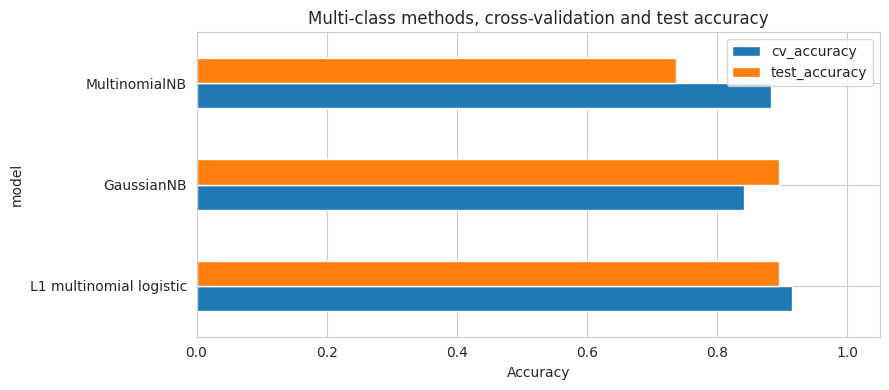

In [33]:
ax = final[["cv_accuracy", "test_accuracy"]].plot(kind="barh", figsize=(9, 4))
ax.set_xlabel("Accuracy")
ax.set_xlim(0, 1.05)
ax.set_title("Multi-class methods, cross-validation and test accuracy")
plt.tight_layout()
plt.show()

L1-penalized multinomial regression is the better method for this problem.

It ties Gaussian Naive Bayes on test accuracy at 0.8947, but it wins everywhere else. Its cross-validation accuracy is 0.9142 against 0.8415, and since cross-validation averages over 69 instances rather than 19 it is the more trustworthy comparison. Its macro AUC is 0.9940 against 0.9643, so it ranks instances better even where the two agree on the hard label. Multinomial Naive Bayes trails both at 0.7368 test accuracy.

The reason is the independence assumption. Naive Bayes treats the features within a class as conditionally independent, and Homework 3 showed that assumption is badly violated here: mean, median, first quartile, and third quartile of the same series correlate above 0.94 with one another. Treating four near-copies of the same measurement as four independent pieces of evidence makes the model overconfident, which is visible in the lower AUC. Multinomial regression has no such assumption, and the L1 penalty handles the correlated features directly by zeroing out all but one of each redundant group, keeping 22 of 42.

Two qualifications are worth stating. With 19 test instances, the difference between 0.8947 and 0.7368 is 3 instances, so none of these rankings is statistically secure. And Naive Bayes retains practical advantages that this comparison does not measure: it trains in a fraction of the time, needs no hyperparameter search at all, and tends to hold up better when training data is very scarce. For this dataset, with 69 training instances and 42 features, the multinomial model is affordable and more accurate, so it is the one to use.

## 3. ISLR 4.8.3

The setup is QDA with one predictor. There are K classes, the prior for class k is written
pi_k, and conditional on class k the predictor is normal with its own mean and its own
variance, so X | Y = k is N(mu_k, sigma_k^2). The density is

f_k(x) = 1 / (sqrt(2*pi) * sigma_k) * exp( -(x - mu_k)^2 / (2 * sigma_k^2) )

By Bayes' theorem the posterior probability of class k is

p_k(x) = pi_k * f_k(x) / sum over l of pi_l * f_l(x)

The Bayes classifier assigns x to whichever class maximizes p_k(x). The denominator does
not depend on k, so it can be dropped, and maximizing p_k(x) is the same as maximizing
pi_k * f_k(x). The logarithm is increasing, so taking logs does not change which class wins:

log( pi_k * f_k(x) ) = log(pi_k) - log(sqrt(2*pi)) - log(sigma_k) - (x - mu_k)^2 / (2 * sigma_k^2)

The term log(sqrt(2*pi)) is the same for every class, so dropping it leaves the discriminant

delta_k(x) = log(pi_k) - log(sigma_k) - (x - mu_k)^2 / (2 * sigma_k^2)

Expanding the square, (x - mu_k)^2 = x^2 - 2*mu_k*x + mu_k^2, and distributing the
denominator gives

delta_k(x) = -x^2 / (2 * sigma_k^2) + mu_k * x / sigma_k^2 - mu_k^2 / (2 * sigma_k^2) + log(pi_k) - log(sigma_k)

Collecting powers of x,

delta_k(x) = a_k * x^2 + b_k * x + c_k

with

a_k = -1 / (2 * sigma_k^2)
b_k = mu_k / sigma_k^2
c_k = -mu_k^2 / (2 * sigma_k^2) + log(pi_k) - log(sigma_k)

so the discriminant is a quadratic function of x, which proves the second half of the claim.

For the first half, take any two classes k and m. The boundary between them is the set of x
where the two discriminants are equal, delta_k(x) = delta_m(x), that is

(a_k - a_m) * x^2 + (b_k - b_m) * x + (c_k - c_m) = 0

The coefficient on x^2 is

a_k - a_m = -1 / (2 * sigma_k^2) + 1 / (2 * sigma_m^2)

which is zero only when sigma_k^2 = sigma_m^2. QDA does not assume equal variances, so in
general this coefficient is nonzero and the boundary is the solution set of a genuine
quadratic equation in x, not a linear one. The Bayes classifier is therefore not linear.

The contrast with LDA makes the role of the assumption clear. If sigma_1^2 = ... = sigma_K^2
= sigma^2, then a_k = -1 / (2 * sigma^2) for every k, the x^2 terms are identical across
classes and cancel in the difference, and what remains is linear in x. The quadratic
behavior comes entirely from letting each class keep its own variance.

One geometric remark. A quadratic equation in one variable has at most two roots, so unlike
LDA, where each pairwise boundary is a single point, QDA can cut the line at two points and
assign a class to an interval with the other class on both sides of it. That is a decision
rule no linear classifier can produce.

## 4. ISLR 4.8.7

Let Y = Yes mean the company issued a dividend. We are given that X given Yes is
N(10, 36), X given No is N(0, 36), the prior for Yes is 0.80 and for No is 0.20, and the
common variance is 36 so the standard deviation is 6. The value to classify is x = 4.

Bayes' theorem gives

P(Yes | X = 4) = pi_Yes * f_Yes(4) / ( pi_Yes * f_Yes(4) + pi_No * f_No(4) )

where f is the normal density

f(x) = 1 / sqrt(2 * pi * sigma^2) * exp( -(x - mu)^2 / (2 * sigma^2) )

Evaluating each density at x = 4:

f_Yes(4) = 1 / (6 * sqrt(2*pi)) * exp( -(4 - 10)^2 / 72 ) = 1 / (6 * sqrt(2*pi)) * exp(-36/72) = 1 / (6 * sqrt(2*pi)) * exp(-0.5)

f_No(4) = 1 / (6 * sqrt(2*pi)) * exp( -(4 - 0)^2 / 72 ) = 1 / (6 * sqrt(2*pi)) * exp(-16/72) = 1 / (6 * sqrt(2*pi)) * exp(-2/9)

The leading constant 1 / (6 * sqrt(2*pi)) is identical in both and cancels, which leaves

P(Yes | X = 4) = 0.80 * exp(-0.5) / ( 0.80 * exp(-0.5) + 0.20 * exp(-2/9) )

Numerically, exp(-0.5) = 0.606531 and exp(-2/9) = 0.800737, so

numerator = 0.80 * 0.606531 = 0.485225
denominator = 0.485225 + 0.20 * 0.800737 = 0.485225 + 0.160147 = 0.645372

P(Yes | X = 4) = 0.485225 / 0.645372 = 0.7519

So the probability that a company with 4 percent profit last year issues a dividend this
year is about 0.752, or 75.2 percent.

Worth noting is that x = 4 is closer to the mean for non-issuers (0) than to the mean for
issuers (10), so the likelihood alone favors No, with f_No(4) = 0.0532 against
f_Yes(4) = 0.0403. The prediction comes out Yes anyway because the prior is lopsided: 80
percent of companies issue dividends, and that four-to-one prior outweighs the modest
likelihood advantage. Since the posterior exceeds 0.5, the Bayes classifier predicts Yes.

In [34]:
from scipy.stats import norm

mu_yes, mu_no, sigma = 10, 0, np.sqrt(36)
pi_yes, pi_no, x = 0.80, 0.20, 4

f_yes = norm.pdf(x, mu_yes, sigma)
f_no = norm.pdf(x, mu_no, sigma)
posterior = pi_yes * f_yes / (pi_yes * f_yes + pi_no * f_no)

print("f_Yes(4) =", round(f_yes, 6))
print("f_No(4)  =", round(f_no, 6))
print("exp(-0.5) =", round(np.exp(-0.5), 6), "  exp(-2/9) =", round(np.exp(-2 / 9), 6))
print("numerator   =", round(pi_yes * np.exp(-0.5), 6))
print("denominator =", round(pi_yes * np.exp(-0.5) + pi_no * np.exp(-2 / 9), 6))
print()
print("P(Yes | X = 4) =", round(posterior, 6))

f_Yes(4) = 0.040328
f_No(4)  = 0.053241
exp(-0.5) = 0.606531   exp(-2/9) = 0.800737
numerator   = 0.485225
denominator = 0.645372

P(Yes | X = 4) = 0.751852
